In [ ]:
import json
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving shelves.json to shelves.json


In [ ]:
file_name = list(uploaded.keys())[0]

with open(file_name, "r") as f:
    shelf_data = json.load(f)

print("Shelf data loaded successfully!")
print("Number of shelves:", len(shelf_data))

Shelf data loaded successfully!
Number of shelves: 7


In [ ]:
print("SHELF INFORMATION")
print("=" * 40)

for shelf in shelf_data:
    print(
        f"Shelf {shelf['shelf_id']}: "
        f"{shelf['product_count']} products"
    )

SHELF INFORMATION
Shelf 1: 27 products
Shelf 2: 47 products
Shelf 3: 46 products
Shelf 4: 46 products
Shelf 5: 42 products
Shelf 6: 38 products
Shelf 7: 27 products


In [ ]:
uploaded_image = files.upload()

Saving self1.jpg to self1.jpg


In [ ]:
image_name = list(uploaded_image.keys())[0]

image = cv2.imread(os.path.join("/content", image_name))

if image is None:
    raise ValueError("Could not load image.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Image loaded successfully!")
print("Width :", image.shape[1])
print("Height:", image.shape[0])

Image loaded successfully!
Width : 1024
Height: 1024


In [ ]:
gap_data = []

for shelf in shelf_data:

    shelf_id = shelf["shelf_id"]
    products = shelf["products"]

    # Sort products from left to right
    products = sorted(products, key=lambda d: d["center_x"])

    shelf_gaps = []

    for i in range(len(products) - 1):

        current = products[i]
        next_product = products[i + 1]

        # Right edge of current product
        current_right = current["x2"]

        # Left edge of next product
        next_left = next_product["x1"]

        # Empty horizontal space between products
        gap = next_left - current_right

        shelf_gaps.append({
            "left_product_index": i,
            "right_product_index": i + 1,
            "gap": float(gap)
        })

    gap_data.append({
        "shelf_id": shelf_id,
        "gaps": shelf_gaps
    })

print("Horizontal gaps calculated successfully!")

Horizontal gaps calculated successfully!


In [ ]:
for shelf in gap_data:

    print(f"\nSHELF {shelf['shelf_id']}")
    print("-" * 40)

    for gap in shelf["gaps"]:
        print(
            f"Between product "
            f"{gap['left_product_index'] + 1} and "
            f"{gap['right_product_index'] + 1}: "
            f"{gap['gap']:.1f} pixels"
        )


SHELF 1
----------------------------------------
Between product 1 and 2: 6.6 pixels
Between product 2 and 3: 8.3 pixels
Between product 3 and 4: 6.6 pixels
Between product 4 and 5: 3.3 pixels
Between product 5 and 6: 2.9 pixels
Between product 6 and 7: 9.0 pixels
Between product 7 and 8: 6.0 pixels
Between product 8 and 9: 4.2 pixels
Between product 9 and 10: 3.6 pixels
Between product 10 and 11: 5.8 pixels
Between product 11 and 12: 5.3 pixels
Between product 12 and 13: 3.8 pixels
Between product 13 and 14: 218.5 pixels
Between product 14 and 15: 1.1 pixels
Between product 15 and 16: 1.2 pixels
Between product 16 and 17: 1.7 pixels
Between product 17 and 18: 1.3 pixels
Between product 18 and 19: 1.2 pixels
Between product 19 and 20: 2.2 pixels
Between product 20 and 21: 23.8 pixels
Between product 21 and 22: 12.6 pixels
Between product 22 and 23: 0.9 pixels
Between product 23 and 24: 1.1 pixels
Between product 24 and 25: 1.3 pixels
Between product 25 and 26: 1.1 pixels
Between produ

In [ ]:
all_gaps = []

for shelf in gap_data:
    for gap_info in shelf["gaps"]:
        gap = gap_info["gap"]

        if gap >= 0:
            all_gaps.append(gap)

if len(all_gaps) == 0:
    raise ValueError("No valid gaps were found.")

median_gap = np.median(all_gaps)

print("Number of gaps:", len(all_gaps))
print("Median gap:", round(median_gap, 2), "pixels")

Number of gaps: 253
Median gap: 1.78 pixels


In [ ]:
gap_threshold = max(median_gap * 2.5, 20)

print("Median gap:", round(median_gap, 2), "pixels")
print("Candidate gap threshold:", round(gap_threshold, 2), "pixels")

Median gap: 1.78 pixels
Candidate gap threshold: 20 pixels


In [ ]:
candidate_gaps = []

for shelf in gap_data:

    shelf_id = shelf["shelf_id"]

    for gap_info in shelf["gaps"]:

        if gap_info["gap"] > gap_threshold:

            candidate_gaps.append({
                "shelf_id": shelf_id,
                "left_product_index": gap_info["left_product_index"],
                "right_product_index": gap_info["right_product_index"],
                "gap": gap_info["gap"]
            })

print("Candidate gaps found:", len(candidate_gaps))

Candidate gaps found: 6


In [ ]:
print("CANDIDATE GAPS")
print("=" * 50)

if len(candidate_gaps) == 0:
    print("No unusually large gaps detected.")

else:
    for i, gap in enumerate(candidate_gaps, start=1):

        print(
            f"Gap {i}: "
            f"Shelf {gap['shelf_id']} | "
            f"Between products "
            f"{gap['left_product_index'] + 1} and "
            f"{gap['right_product_index'] + 1} | "
            f"Size = {gap['gap']:.1f} px"
        )

CANDIDATE GAPS
Gap 1: Shelf 1 | Between products 13 and 14 | Size = 218.5 px
Gap 2: Shelf 1 | Between products 20 and 21 | Size = 23.8 px
Gap 3: Shelf 5 | Between products 14 and 15 | Size = 54.9 px
Gap 4: Shelf 6 | Between products 12 and 13 | Size = 91.1 px
Gap 5: Shelf 6 | Between products 18 and 19 | Size = 35.0 px
Gap 6: Shelf 7 | Between products 18 and 19 | Size = 320.9 px


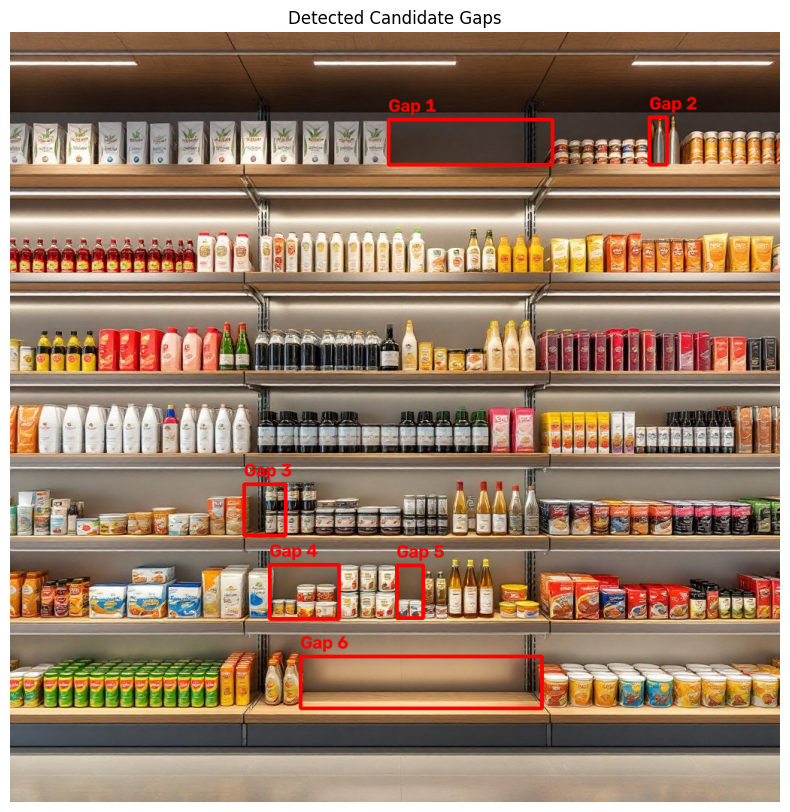

In [ ]:
gap_image = image.copy()

for i, candidate in enumerate(candidate_gaps, start=1):

    shelf_id = candidate["shelf_id"]

    shelf = next(
        shelf for shelf in shelf_data
        if shelf["shelf_id"] == shelf_id
    )

    products = sorted(
        shelf["products"],
        key=lambda d: d["center_x"]
    )

    left_product = products[candidate["left_product_index"]]
    right_product = products[candidate["right_product_index"]]

    # Gap boundaries
    x1 = int(left_product["x2"])
    x2 = int(right_product["x1"])

    y1 = int(min(left_product["y1"], right_product["y1"]))
    y2 = int(max(left_product["y2"], right_product["y2"]))

    # Draw candidate gap
    cv2.rectangle(
        gap_image,
        (x1, y1),
        (x2, y2),
        (0, 0, 255),
        3
    )

    # Label
    cv2.putText(
        gap_image,
        f"Gap {i}",
        (x1, max(30, y1 - 10)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 0, 255),
        2
    )

gap_rgb = cv2.cvtColor(gap_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(16, 10))
plt.imshow(gap_rgb)
plt.axis("off")
plt.title("Detected Candidate Gaps")
plt.show()

In [ ]:
estimated_positions = []

for candidate in candidate_gaps:

    shelf = next(
        shelf for shelf in shelf_data
        if shelf["shelf_id"] == candidate["shelf_id"]
    )

    products = sorted(
        shelf["products"],
        key=lambda d: d["center_x"]
    )

    left_product = products[candidate["left_product_index"]]
    right_product = products[candidate["right_product_index"]]

    # Estimate position halfway through the gap
    estimated_x = (
        left_product["x2"] +
        right_product["x1"]
    ) / 2

    estimated_y = (
        left_product["center_y"] +
        right_product["center_y"]
    ) / 2

    estimated_positions.append({
        "shelf_id": candidate["shelf_id"],
        "gap": candidate["gap"],
        "estimated_x": float(estimated_x),
        "estimated_y": float(estimated_y)
    })

print("Estimated missing-product positions:")
print()

for position in estimated_positions:

    print(
        f"Shelf {position['shelf_id']}: "
        f"x={position['estimated_x']:.1f}, "
        f"y={position['estimated_y']:.1f}, "
        f"gap={position['gap']:.1f}px"
    )

Estimated missing-product positions:

Shelf 1: x=612.6, y=152.6, gap=218.5px
Shelf 1: x=862.0, y=151.7, gap=23.8px
Shelf 5: x=339.4, y=639.1, gap=54.9px
Shelf 6: x=391.5, y=737.5, gap=91.1px
Shelf 6: x=531.9, y=737.6, gap=35.0px
Shelf 7: x=547.2, y=869.2, gap=320.9px


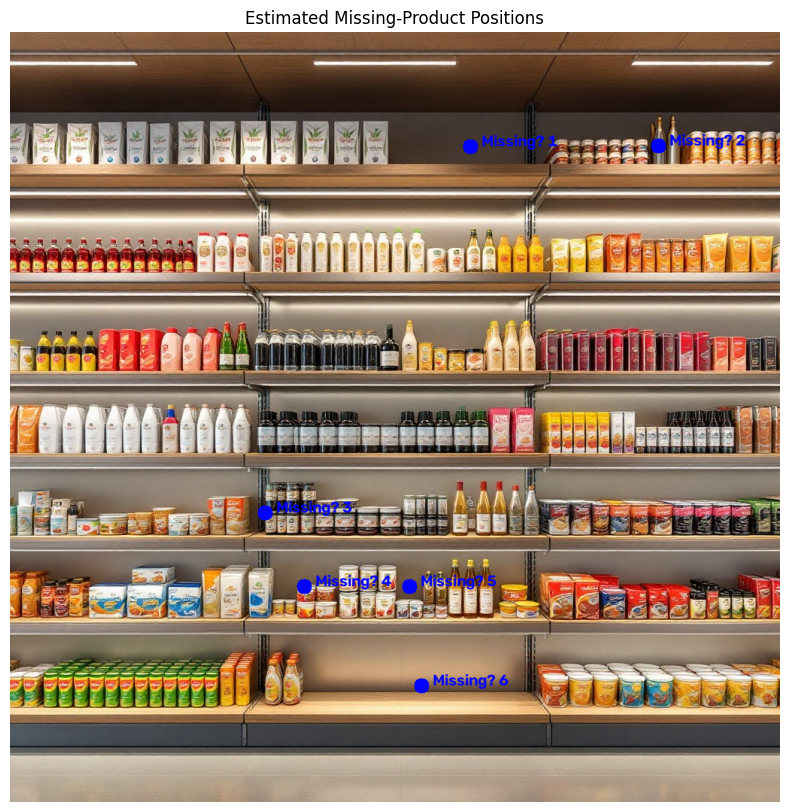

In [ ]:
position_image = image.copy()

for i, position in enumerate(estimated_positions, start=1):

    x = int(position["estimated_x"])
    y = int(position["estimated_y"])

    cv2.circle(
        position_image,
        (x, y),
        10,
        (255, 0, 0),
        -1
    )

    cv2.putText(
        position_image,
        f"Missing? {i}",
        (x + 15, y),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 0, 0),
        2
    )

position_rgb = cv2.cvtColor(position_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(16, 10))
plt.imshow(position_rgb)
plt.axis("off")
plt.title("Estimated Missing-Product Positions")
plt.show()

In [ ]:
output_path = "/content/gaps.json"

with open(output_path, "w") as f:
    json.dump(
        {
            "median_gap": float(median_gap),
            "gap_threshold": float(gap_threshold),
            "candidate_gaps": candidate_gaps,
            "estimated_positions": estimated_positions
        },
        f,
        indent=4
    )

print("Gap data saved to:")
print(output_path)

Gap data saved to:
/content/gaps.json


In [ ]:
files.download("/content/gaps.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>